### Import the Dataset from SportsDataverse

In [ ]:
pip install sportsdataverse

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/19.1 MB ? eta -:--:--

In [ ]:
import sportsdataverse.pwhl
import sportsdataverse.nhl

In [ ]:
from sportsdataverse import pwhl
import pandas as pd
from sportsdataverse.pwhl import (
    load_pwhl_game_info, load_pwhl_team_boxscores, load_pwhl_schedules, load_pwhl_scoring_summary
)
from sportsdataverse.nhl import (
    load_nhl_game_info, load_nhl_team_boxscores
)

# Define what to load per league
pwhl_2026 = {
    "game_info": load_pwhl_game_info(2026),
    "team_boxscores": load_pwhl_team_boxscores(2026),
    "scoring_summary": load_pwhl_scoring_summary(2026),
    #"schedules": load_pwhl_schedules(2026)
}

nhl_2026 = {
    "game_info": load_nhl_game_info(2026),
    "player_boxscores":load_nhl_team_boxscores(2026),
}

pwhl_2025 = {
    "game_info": load_pwhl_game_info(2025),
    "team_boxscores": load_pwhl_team_boxscores(2025),
    "scoring_summary": load_pwhl_scoring_summary(2025),
    #"schedules": load_pwhl_schedules(2025)
}

nhl_2025 = {
    "game_info": load_nhl_game_info(2025),
    "goalie_boxscores": load_nhl_team_boxscores(2025),
}

pwhl_2024 = {
    "game_info": load_pwhl_game_info(2024),
    "team_boxscores": load_pwhl_team_boxscores(2024),
    "scoring_summary": load_pwhl_scoring_summary(2024),
    #"schedules": load_pwhl_schedules(2024)
}

nhl_2024 = {
    "game_info": load_nhl_game_info(2024),
    "goalie_boxscores": load_nhl_team_boxscores(2024),
}

In [ ]:
# check dataframe type
print(type(pwhl_2026["game_info"]))

In [ ]:
import pandas as pd
# convert polars to pd.dataframe
def to_pandas_season(season_dict):
    return {name: df.to_pandas() for name, df in season_dict.items()}

pwhl_2026 = to_pandas_season(pwhl_2026)
nhl_2026  = to_pandas_season(nhl_2026)
pwhl_2025 = to_pandas_season(pwhl_2025)
nhl_2025  = to_pandas_season(nhl_2025)
pwhl_2024 = to_pandas_season(pwhl_2024)
nhl_2024  = to_pandas_season(nhl_2024)

# schedule loader would get error so an alternative way was found
# and be intergrated with the rest
sched_2026 = pd.read_parquet("https://github.com/sportsdataverse/sportsdataverse-data/releases/download/pwhl_schedules/pwhl_schedule_2026.parquet", engine="pyarrow")
sched_2025 = pd.read_parquet("https://github.com/sportsdataverse/sportsdataverse-data/releases/download/pwhl_schedules/pwhl_schedule_2025.parquet", engine="pyarrow")
sched_2024 = pd.read_parquet("https://github.com/sportsdataverse/sportsdataverse-data/releases/download/pwhl_schedules/pwhl_schedule_2024.parquet", engine="pyarrow")

pwhl_2026["schedules"] = sched_2026
pwhl_2025["schedules"] = sched_2025
pwhl_2024["schedules"] = sched_2024

### Clean the Data

In [ ]:
def null_summary(df):
    """Return a DataFrame summarizing null counts and percentages per column."""
    counts = df.isnull().sum()
    pct = df.isnull().mean() * 100
    summary = pd.DataFrame({
        "null_count": counts,
        "null_pct": pct.round(2),
        "dtype": df.dtypes.astype(str),
    }).sort_values("null_pct", ascending=False)
    return summary

#print(null_summary(pwhl_2026["pbp"]))

In [ ]:
pwhl_2026['game_info'].shape

In [ ]:
def remove_null_columns(df, threshold=0.5, verbose=True):
    null_fraction = df.isnull().mean()
    cols_to_keep = null_fraction[null_fraction < threshold].index.tolist()
    dropped = [c for c in df.columns if c not in cols_to_keep]

    if verbose and dropped:
        pct = (threshold * 100)
        print(f"Dropped {len(dropped)} column(s) with >= {pct:.0f}% nulls:")
        for c in dropped:
            print(f"  - {c} ({null_fraction[c]:.1%} null)")

    return df[cols_to_keep].copy()

In [ ]:
def clean_season(season_dict, threshold=0.5, verbose=True):
    for name, df in season_dict.items():
        if verbose:
            print(f"\n--- {name} ---")
        season_dict[name] = remove_null_columns(df, threshold=threshold, verbose=verbose)
    return season_dict

pwhl_2026 = clean_season(pwhl_2026, threshold=1)
nhl_2026  = clean_season(nhl_2026,  threshold=1)
pwhl_2025 = clean_season(pwhl_2025, threshold=1)
nhl_2025  = clean_season(nhl_2025,  threshold=1)
pwhl_2024 = clean_season(pwhl_2024, threshold=1)
nhl_2024  = clean_season(nhl_2024,  threshold=1)

In [ ]:
s2026 = pwhl_2026['schedules']['game_date']
#print(s2026.head(10))
s2025 = pwhl_2025['schedules']['game_date']
#print(s2025.head(10))
s2024 = pwhl_2024['schedules']['game_date']
#print(s2024.head(10))

In [ ]:
def _to_date(s: pd.Series, season_year: int) -> pd.Series:
    """
    Parse 'Wed, Nov 26' -> datetime, attaching season_year.
    PWHL seasons span Oct-Jun, so a Nov date is in season_year;
    a Jan-Jun date could be season_year+? — see note below.
    """
    s = s.astype("object").str.strip()

    # Strip the weekday prefix: 'Wed, Nov 26' -> 'Nov 26'
    s = s.str.replace(r"^[A-Za-z]{3},\s*", "", regex=True)

    # Parse month-day, then attach the year
    out = pd.to_datetime(
        s + f" {season_year}",
        format="%b %d %Y",
        errors="coerce",
    )

    n_bad = out.isna().sum() - s.isna().sum()
    if n_bad:
        print(f"  [warn] {n_bad} game_date value(s) failed to parse")
        print(s[out.isna() & s.notna()].head().tolist())

    return out

def _to_date_season(s: pd.Series, season_end_year: int) -> pd.Series:
    s = s.astype("object").str.strip()
    s = s.str.replace(r"^[A-Za-z]{3},\s*", "", regex=True)
    md = pd.to_datetime(s + " 2000", format="%b %d %Y", errors="coerce")
    month = md.dt.month
    year = pd.Series(season_end_year, index=s.index)
    year = year.where(month <= 6, season_end_year - 1)

    # Debug: print a few
    debug = pd.DataFrame({"raw": s, "month": month, "assigned_year": year}).head(10)
    print(debug)

    out = pd.to_datetime(s + " " + year.astype(str), format="%b %d %Y", errors="coerce")
    return out

date2026 = _to_date(s2026, 2026)
date2026 = _to_date_season(s2026, 2026)
pwhl_2026['schedules']['game_date'] = date2026
date2025 = _to_date(s2025, 2025)
date2025 = _to_date_season(s2025, 2025)
pwhl_2025['schedules']['game_date'] = date2025
date2024 = _to_date(s2024, 2024)
date2024 = _to_date_season(s2024, 2024)
pwhl_2024['schedules']['game_date'] = date2024

In [ ]:
#print(sorted(pwhl_2026['schedules']['game_date']))
#print(sorted(pwhl_2025['schedules']['game_date']))
#print(sorted(pwhl_2024['schedules']['game_date']))

### Observations / Expoloration

Feature Names

In [ ]:
pwhl_2026['game_info'].columns

In [ ]:
pwhl_2026['schedules'].columns

In [ ]:
pwhl_2026['team_boxscores'].columns

Summaries

In [ ]:
print(pwhl_2026['game_info'].describe())
print(pwhl_2025['game_info'].describe())
print(pwhl_2024['game_info'].describe())

In [ ]:
print(pwhl_2026['schedules'].describe())
print(pwhl_2025['schedules'].describe())
print(pwhl_2024['schedules'].describe())

In [ ]:
print(pwhl_2026['team_boxscores'].describe())
print(pwhl_2025['team_boxscores'].describe())
print(pwhl_2024['team_boxscores'].describe())

Visualiztion on Goals

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
def shots_vs_goals(team_box, season_label):
    # per-team per-game averages
    agg = (team_box.groupby("team_id")
                   .agg(shots_pg=("shots", "mean"),
                        goals_pg=("goals", "mean"),
                        games=("game_id", "nunique"))
                   .reset_index())

    fig, ax = plt.subplots(figsize=(8, 6))
    sc = ax.scatter(agg["shots_pg"], agg["goals_pg"],
                    s=agg["games"] * 4, alpha=0.7, color="crimson")
    for _, r in agg.iterrows():
        ax.annotate(str(int(r["team_id"])),
                    (r["shots_pg"], r["goals_pg"]),
                    fontsize=8, ha="center", va="center")
    ax.set_xlabel("Shots per game")
    ax.set_ylabel("Goals per game")
    ax.set_title(f"{season_label} — shots vs goals per game (bubble = games played)")
    plt.tight_layout(); plt.show()

for yr, d in [("2024", pwhl_2024), ("2025", pwhl_2025), ("2026", pwhl_2026)]:
    shots_vs_goals(d["team_boxscores"], f"PWHL {yr}")

In [ ]:
def home_away_goals(team_box, season_label):
    tb = team_box.copy()
    # team_side is typically 'home'/'away'/'neutral'
    tb["side"] = tb["team_side"].astype(str).str.lower().str.strip()

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # left: box plot of goals by side
    data = [tb.loc[tb["side"] == s, "goals"].dropna() for s in ["home", "away"]]
    axes[0].boxplot(data, labels=["home", "away"])
    axes[0].set_ylabel("Goals per game")
    axes[0].set_title(f"{season_label} — goals by side")

    # right: shots by side
    data2 = [tb.loc[tb["side"] == s, "shots"].dropna() for s in ["home", "away"]]
    axes[1].boxplot(data2, labels=["home", "away"])
    axes[1].set_ylabel("Shots per game")
    axes[1].set_title(f"{season_label} — shots by side")

    plt.tight_layout(); plt.show()

    # numeric summary to quote in the report
    print(tb.groupby("side")[["goals", "shots"]].mean().round(2))

for yr, d in [("2024", pwhl_2024), ("2025", pwhl_2025), ("2026", pwhl_2026)]:
    home_away_goals(d["team_boxscores"], f"PWHL {yr}")

In [ ]:
# correlation heatmap — screens all columns for redundancy + signal
import seaborn as sns

def corr_heatmap(team_box, label):
    tb = team_box.copy()
    if "goals_against" not in tb.columns:
        opp = tb[["game_id","team_id","goals"]].rename(
            columns={"team_id":"opp_id","goals":"goals_against"})
        tb = tb.merge(opp, on="game_id", how="left")
        tb = tb[tb["team_id"] != tb["opp_id"]]
    num = tb.select_dtypes("number").drop(columns=["game_id","team_id"], errors="ignore")
    plt.figure(figsize=(10,8))
    sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
    plt.title(f"{label} — team boxscore correlations")
    plt.tight_layout(); plt.show()

corr_heatmap(pwhl_2026["team_boxscores"], "PWHL 2026")

### Setting Up for ML Training

In [ ]:
def build_game_table(game_info, team_box, sched, scoring_summary=None):
    game_info = game_info.copy(); team_box = team_box.copy(); sched = sched.copy()

    for df in (game_info, team_box, sched):
        df["game_id"] = df["game_id"].astype(str)

    tb = team_box.merge(
        sched[["game_id","game_date","home_team_id","away_team_id"]],
        on="game_id", how="left"
    ).sort_values(["team_id","game_date"])

    for c in ("team_id","home_team_id","away_team_id"):
        tb[c] = tb[c].astype(str)

    print("home matches:", (tb["team_id"] == tb["home_team_id"]).sum())
    print("away matches:", (tb["team_id"] == tb["away_team_id"]).sum())

    # rolling goals/shots + rest
    for col in ["goals","shots"]:
        tb[f"{col}_roll5"] = (tb.groupby("team_id")[col]
            .transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean()))
    tb["days_rest"] = tb.groupby("team_id")["game_date"].transform(lambda s: s.diff().dt.days)
    tb["b2b"] = (tb["days_rest"] == 1).astype(int)

    feat = ["goals_roll5","shots_roll5","days_rest","b2b"]

    # optional: distinct scorers per team per game, shifted + rolled
    if scoring_summary is not None:
        ss = scoring_summary.copy()
        ss["game_id"] = ss["game_id"].astype(str)
        ss["team_id"] = ss["team_id"].astype(str)

        scorers = (ss.groupby(["game_id","team_id"])["scorer_id"]
                     .nunique().reset_index()
                     .rename(columns={"scorer_id": "n_scorers"}))

        tb = tb.merge(scorers, on=["game_id","team_id"], how="left")
        tb["n_scorers"] = tb["n_scorers"].fillna(0)

        tb["n_scorers_roll5"] = (tb.groupby("team_id")["n_scorers"]
            .transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean()))
        feat.append("n_scorers_roll5")

    home = tb[tb["team_id"] == tb["home_team_id"]][["game_id"]+feat].copy()
    home.columns = ["game_id"] + [f"home_{c}" for c in feat]
    away = tb[tb["team_id"] == tb["away_team_id"]][["game_id"]+feat].copy()
    away.columns = ["game_id"] + [f"away_{c}" for c in feat]

    gi = game_info[["game_id","home_score","away_score"]].copy()
    gi["home_win"]  = (gi["home_score"] > gi["away_score"]).astype(int)
    gi["goal_diff"] = gi["home_score"] - gi["away_score"]
    return gi.merge(home, on="game_id", how="left").merge(away, on="game_id", how="left")


pwhl_games = pd.concat([
    build_game_table(
        d["game_info"],
        d["team_boxscores"],
        d["schedules"],
        d["scoring_summary"].to_pandas() if hasattr(d["scoring_summary"], "to_pandas") else d["scoring_summary"],
    ).assign(season=y)
    for y, d in [(2024, pwhl_2024), (2025, pwhl_2025), (2026, pwhl_2026)]
], ignore_index=True)

print(pwhl_games.shape)
print(pwhl_games.isnull().sum())
print(pwhl_games.head(5))

In [ ]:
# 1. differentials (combine home and away into one column)
pwhl_games["goals_diff_roll5"] = pwhl_games["home_goals_roll5"] - pwhl_games["away_goals_roll5"]
pwhl_games["shots_diff_roll5"] = pwhl_games["home_shots_roll5"] - pwhl_games["away_shots_roll5"]
pwhl_games["rest_diff"]        = pwhl_games["home_days_rest"]   - pwhl_games["away_days_rest"]

# 2. shooting percentage differential (finishing quality)
pwhl_games["home_sh_pct"] = pwhl_games["home_goals_roll5"] / pwhl_games["home_shots_roll5"].replace(0, pd.NA)
pwhl_games["away_sh_pct"] = pwhl_games["away_goals_roll5"] / pwhl_games["away_shots_roll5"].replace(0, pd.NA)
pwhl_games["sh_pct_diff"] = pwhl_games["home_sh_pct"] - pwhl_games["away_sh_pct"]

# 3. score differential interaction with rest (one interaction, sparingly)
pwhl_games["goals_diff_x_rest"] = pwhl_games["goals_diff_roll5"] * pwhl_games["rest_diff"]

In [ ]:
def to_team_game_target(pwhl_games):
    """Reshape one-row-per-game into one-row-per-team-game with a single `win` target."""
    cols = ["game_id", "season",
            "goals_roll5", "shots_roll5", "days_rest", "b2b", "n_scorers_roll5"]

    home = pwhl_games[["game_id", "season",
                       "home_goals_roll5", "home_shots_roll5",
                       "home_days_rest", "home_b2b", "home_n_scorers_roll5",
                       "home_score", "away_score"]].copy()
    home.columns = ["game_id", "season"] + cols[2:] + ["goals_for", "goals_against"]
    home["is_home"] = 1

    away = pwhl_games[["game_id", "season",
                       "away_goals_roll5", "away_shots_roll5",
                       "away_days_rest", "away_b2b", "away_n_scorers_roll5",
                       "away_score", "home_score"]].copy()
    away.columns = ["game_id", "season"] + cols[2:] + ["goals_for", "goals_against"]
    away["is_home"] = 0

    tg = pd.concat([home, away], ignore_index=True)
    tg["win"] = (tg["goals_for"] > tg["goals_against"]).astype(int)
    return tg

pwhl_games = to_team_game_target(pwhl_games)
print(pwhl_games.shape)

(640, 11)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
# --- feature list ---
feature_cols = []

df = pwhl_games
X = df[feature_cols]
y = df["win"]

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# --- fit on train only ---
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

logreg_pred = model.predict(X_test)

KeyError: "None of [Index(['home_goals_roll5', 'away_goals_roll5', 'home_shots_roll5',\n       'away_shots_roll5', 'goals_diff_roll5', 'shots_diff_roll5',\n       'sh_pct_diff', 'home_days_rest', 'away_days_rest', 'home_b2b',\n       'away_b2b', 'rest_diff', 'goals_diff_x_rest'],\n      dtype='str')] are in the [columns]"

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

In [ ]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=300, max_depth=3, learning_rate=0.05,
    random_state=42, eval_metric="logloss", verbosity=0
)
xgb.fit(X_train, y_train)
xgb_pred = xgb.predict(X_test)


In [ ]:
from sklearn.svm import SVC

svc = SVC(kernel="rbf", probability=True, random_state=42)
svc.fit(X_train, y_train)

svc_pred = svc.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

def evaluate_model(model_name, y_test, y_pred):
    accuracy  = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall    = recall_score(y_test, y_pred, zero_division=0)

    print(f"\n{model_name} Performance:")
    print(f"  Accuracy:  {accuracy:.4f}")
    print(f"  Precision: {precision:.4f}")
    print(f"  Recall:    {recall:.4f}")

    return accuracy, precision, recall

# evaluate
lr_acc,  lr_prec,  lr_rec  = evaluate_model("Logistic Regression", y_test, logreg_pred)
rf_acc,  rf_prec,  rf_rec  = evaluate_model("Random Forest", y_test, rf_pred)
xgb_acc, xgb_prec, xgb_rec = evaluate_model("XGBoost", y_test, xgb_pred)
svc_acc, svc_prec, svc_rec = evaluate_model("SVC (RBF)", y_test, svc_pred)


Logistic Regression Performance:
  Accuracy:  0.4516
  Precision: 0.5094
  Recall:    0.7714

Random Forest Performance:
  Accuracy:  0.5161
  Precision: 0.5581
  Recall:    0.6857

XGBoost Performance:
  Accuracy:  0.5484
  Precision: 0.5897
  Recall:    0.6571

SVC (RBF) Performance:
  Accuracy:  0.5645
  Precision: 0.5645
  Recall:    1.0000


In [ ]:
from sklearn.dummy import DummyClassifier
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)
d_acc, d_prec, d_rec = evaluate_model("Always predict majority", y_test, dummy_pred)


Always predict majority Performance:
  Accuracy:  0.5645
  Precision: 0.5645
  Recall:    1.0000


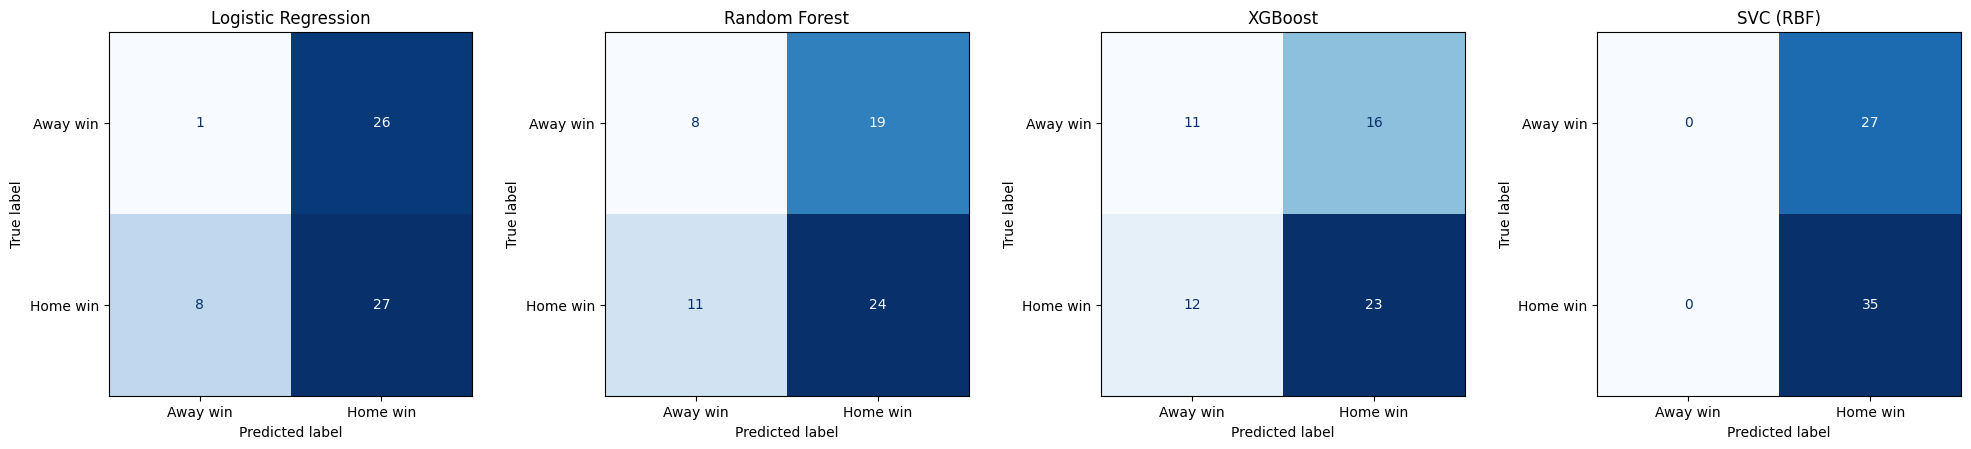

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

models_preds = {
    "Logistic Regression": logreg_pred,
    "Random Forest": rf_pred,
    "XGBoost": xgb_pred,
    "SVC (RBF)": svc_pred,
}

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (name, pred) in zip(axes, models_preds.items()):
    cm = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=["Away win", "Home win"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

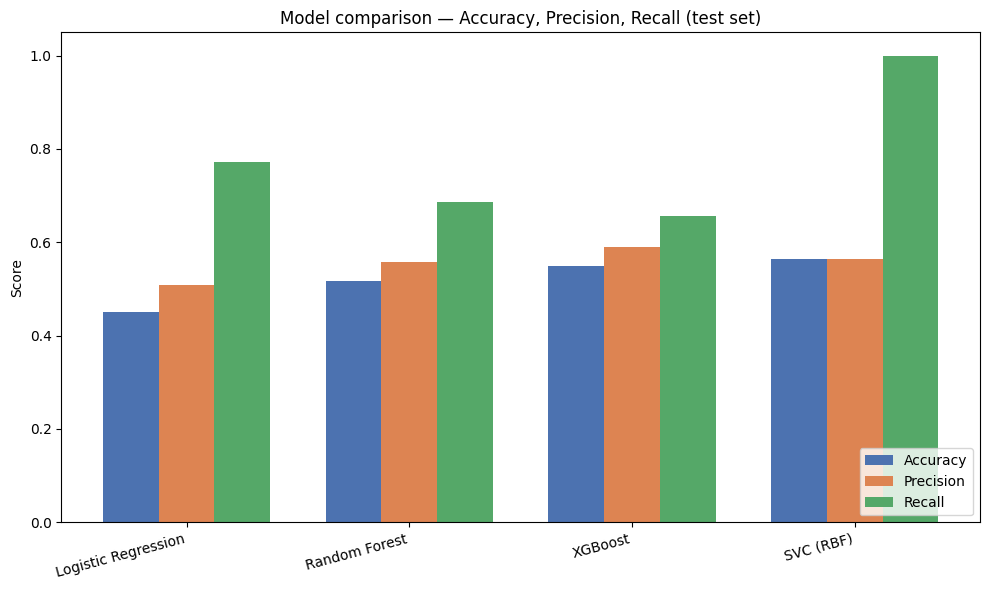

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

model_names = ["Logistic Regression", "Random Forest", "XGBoost", "SVC (RBF)"]
accuracy = [lr_acc,  rf_acc,  xgb_acc,  svc_acc]
precision = [lr_prec, rf_prec, xgb_prec, svc_prec]
recall = [lr_rec,  rf_rec,  xgb_rec,  svc_rec]

x = np.arange(len(model_names))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - width, accuracy, width, label="Accuracy", color="#4C72B0")
ax.bar(x, precision, width, label="Precision", color="#DD8452")
ax.bar(x + width, recall, width, label="Recall", color="#55A868")

ax.set_xticks(x)
ax.set_xticklabels(model_names, rotation=15, ha="right")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.set_title("Model comparison — Accuracy, Precision, Recall (test set)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

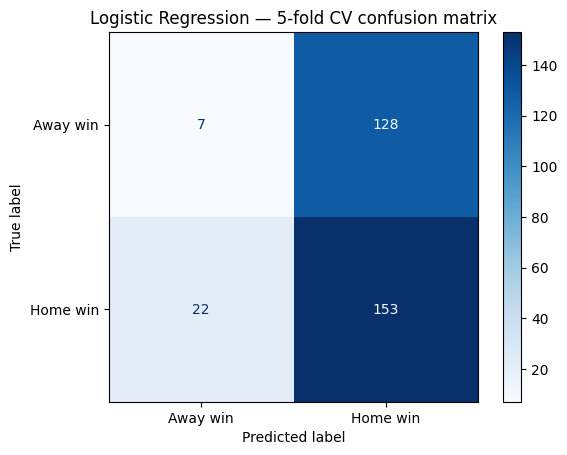

In [ ]:
from sklearn.model_selection import cross_val_predict
cv_pred = cross_val_predict(LogisticRegression(max_iter=1000), X, y, cv=5)
cm = confusion_matrix(y, cv_pred)
ConfusionMatrixDisplay(cm, display_labels=["Away win", "Home win"]).plot(cmap="Blues")
plt.title("Logistic Regression — 5-fold CV confusion matrix")
plt.show()